# NovaPay Fraud Detection Pipeline
Profile → Prepare → Explore → Model → Explain → Deploy → Monitor

## Setup

In [1]:
%pip install -q optuna shap xgboost lightgbm statsmodels fastapi "uvicorn[standard]" evidently

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("nova_pay_combined.csv")

In [4]:
df.head()

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,...,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,...,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,...,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,...,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


## Step 1: Data Collection & Profiling

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             11400 non-null  object 
 1   customer_id                11400 non-null  object 
 2   timestamp                  11371 non-null  object 
 3   home_country               11400 non-null  object 
 4   source_currency            11400 non-null  object 
 5   dest_currency              11400 non-null  object 
 6   channel                    11400 non-null  object 
 7   amount_src                 11400 non-null  object 
 8   amount_usd                 11095 non-null  float64
 9   fee                        11105 non-null  float64
 10  exchange_rate_src_to_dest  11400 non-null  float64
 11  device_id                  11400 non-null  object 
 12  new_device                 11400 non-null  bool   
 13  ip_address                 11095 non-null  obj

In [6]:
df.isnull().mean()*100

transaction_id               0.000000
customer_id                  0.000000
timestamp                    0.254386
home_country                 0.000000
source_currency              0.000000
dest_currency                0.000000
channel                      0.000000
amount_src                   0.000000
amount_usd                   2.675439
fee                          2.587719
exchange_rate_src_to_dest    0.000000
device_id                    0.000000
new_device                   0.000000
ip_address                   2.675439
ip_country                   2.640351
location_mismatch            0.000000
ip_risk_score                0.000000
kyc_tier                     2.631579
account_age_days             0.000000
device_trust_score           2.587719
chargeback_history_count     0.000000
risk_score_internal          0.000000
txn_velocity_1h              0.000000
txn_velocity_24h             0.000000
corridor_risk                0.000000
is_fraud                     0.000000
dtype: float

In [7]:
df.describe()

,amount_usd,fee,exchange_rate_src_to_dest,ip_risk_score,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
count,11095.000000,11105.000000,11400.000000,11400.000000,11400.000000,11105.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000
mean,452.022083,100.309441,167.540397,0.396726,393.793158,0.653681,0.048509,0.267134,0.458333,0.723509,0.045501,0.087456
std,1403.973062,958.128504,382.023827,0.270507,342.348393,0.273012,0.256194,0.142983,1.524494,1.958390,0.084942,0.282515
min,7.230000,-1.000000,0.592000,0.004000,1.000000,-0.100000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000
25%,92.465000,2.380000,1.000000,0.209000,147.000000,0.515000,0.000000,0.169000,0.000000,0.000000,0.000000,0.000000
50%,163.480000,3.500000,7.142857,0.325000,298.000000,0.658000,0.000000,0.223000,0.000000,0.000000,0.000000,0.000000
75%,302.190000,5.550000,73.529412,0.487000,661.000000,0.894000,0.000000,0.391000,0.000000,0.000000,0.050000,0.000000
max,12498.570000,9999.990000,1388.888889,1.200000,1095.000000,0.999000,2.000000,0.900000,8.000000,11.000000,0.250000,1.000000


In [8]:
num_cols = df.select_dtypes(include="number").columns
desc = df[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = df[num_cols].skew()
desc["zeros_%"] = (df[num_cols] == 0).mean() * 100
display(desc.round(3))
print("Skew > 1 => right-skewed: consider log1p transform. Large gap between p99 and max => outliers.")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,zeros_%
amount_usd,11095.0,452.022,1403.973,7.230,23.186,41.567,92.465,163.480,302.190,1041.485,9994.351,12498.570,6.509,0.000
fee,11105.0,100.309,958.129,-1.000,0.500,1.340,2.380,3.500,5.550,19.422,152.039,9999.990,10.233,0.000
exchange_rate_src_to_dest,11400.0,167.540,382.024,0.592,0.592,0.800,1.000,7.143,73.529,1111.111,1388.889,1388.889,2.272,0.000
ip_risk_score,11400.0,0.397,0.271,0.004,0.045,0.090,0.209,0.325,0.487,1.000,1.200,1.200,1.222,0.000
account_age_days,11400.0,393.793,342.348,1.000,4.000,4.000,147.000,298.000,661.000,1018.000,1041.010,1095.000,0.786,0.000
device_trust_score,11105.0,0.654,0.273,-0.100,-0.100,0.179,0.515,0.658,0.894,0.944,0.953,0.999,-0.614,0.000
chargeback_history_count,11400.0,0.049,0.256,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,2.000,5.786,96.123
risk_score_internal,11400.0,0.267,0.143,0.000,0.068,0.087,0.169,0.223,0.391,0.489,0.817,0.900,1.486,0.096
txn_velocity_1h,11400.0,0.458,1.524,-1.000,-1.000,0.000,0.000,0.000,0.000,4.000,7.000,8.000,3.234,87.456
txn_velocity_24h,11400.0,0.724,1.958,0.000,0.000,0.000,0.000,0.000,0.000,6.000,9.000,11.000,2.982,81.123


Skew > 1 => right-skewed: consider log1p transform. Large gap between p99 and max => outliers.


In [9]:
TARGET = "is_fraud"
p = df[TARGET].mean()

In [10]:
# Prevalence over time and by hour / weekday (drift check)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

Date range: 2022-10-03 18:40:59.468549+00:00 to 2025-12-16 00:13:41.468549+00:00
Rows dropped (bad timestamp): 61


C:\Users\uSER\AppData\Local\Temp\ipykernel_13536\1642109796.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  t["month"] = t["timestamp"].dt.to_period("M")


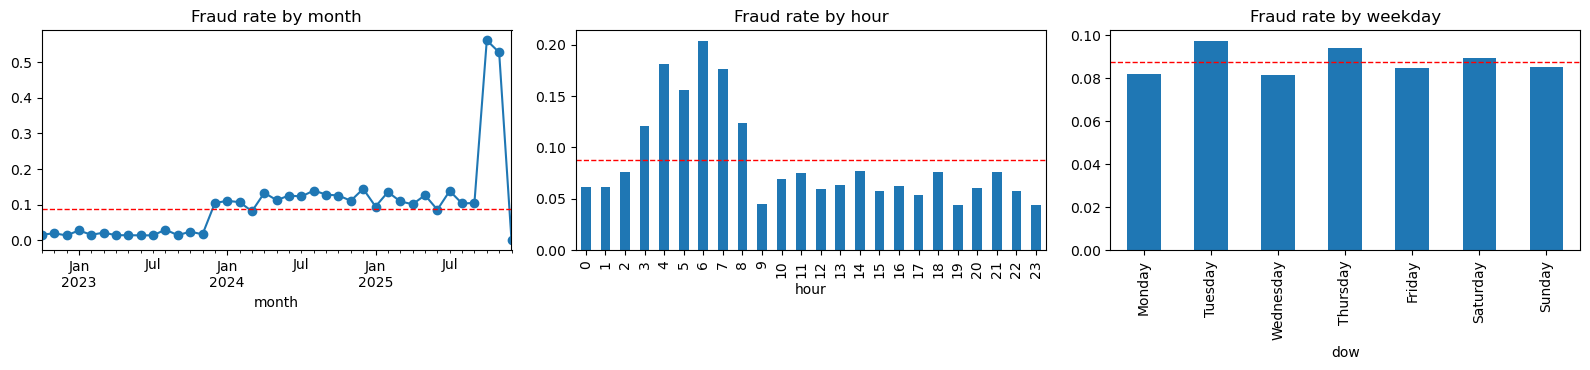

In [11]:
t = df.dropna(subset=["timestamp"]).copy()
t["month"] = t["timestamp"].dt.to_period("M")
t["hour"] = t["timestamp"].dt.hour
t["dow"] = t["timestamp"].dt.day_name()
print("Date range:", t["timestamp"].min(), "to", t["timestamp"].max())
print("Rows dropped (bad timestamp):", len(df) - len(t))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
t.groupby("month")[TARGET].mean().plot(ax=ax[0], marker="o", title="Fraud rate by month")
t.groupby("hour")[TARGET].mean().plot(ax=ax[1], kind="bar", title="Fraud rate by hour")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
t.groupby("dow")[TARGET].mean().reindex(order).plot(ax=ax[2], kind="bar", title="Fraud rate by weekday")
for a in ax:
    a.axhline(p, color="red", ls="--", lw=1)
plt.tight_layout()
plt.show()

In [12]:
num_cols = [c for c in df.select_dtypes(include="number").columns if c != TARGET]

,corr_with_fraud
txn_velocity_24h,0.750
txn_velocity_1h,0.686
risk_score_internal,0.601
chargeback_history_count,0.580
ip_risk_score,0.519
device_trust_score,-0.391
account_age_days,-0.284
corridor_risk,0.193
exchange_rate_src_to_dest,0.152
amount_usd,0.129


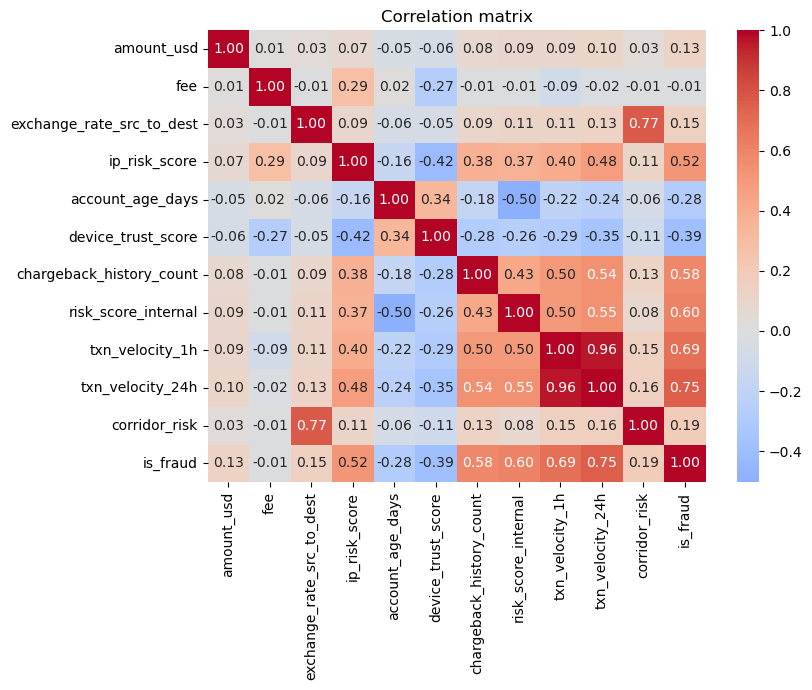

In [13]:
# Correlation of numeric features with the target + among themselves
corr = df[num_cols + [TARGET]].corr()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_fraud"))

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(num_cols) <= 12, fmt=".2f", ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## Step 2: Data Preparation & Feature Engineering

In [14]:
def clean(df):
    df = df.drop_duplicates('transaction_id').copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', errors='coerce')
    df['amount_src'] = pd.to_numeric(df['amount_src'].astype('string').str.replace(r'[,$\s]', '', regex=True), errors='coerce').astype('float64')
    blk = ['amount_usd','fee','ip_address','ip_country','kyc_tier','device_trust_score']
    df['enrichment_missing'] = df[blk].isnull().all(axis=1).astype(int)
    df['timestamp_invalid'] = df['timestamp'].isnull().astype(int)
    df['amount_usd'] = df['amount_usd'].fillna(df['amount_src'] * df['exchange_rate_src_to_dest'])
    for c in ['home_country','ip_country','source_currency','dest_currency','channel','kyc_tier']:
        df[c] = df[c].astype('string').str.strip().str.upper()
    df['channel'] = df['channel'].replace({'MOBILLE': 'MOBILE', 'WEEB': 'WEB'})  # fix typos
    df[['kyc_tier','ip_country']] = df[['kyc_tier','ip_country']].fillna('UNKNOWN')
    return df.sort_values(['timestamp','transaction_id'], na_position='first').reset_index(drop=True)

df_clean = clean(df)
print(df_clean.shape, df_clean['enrichment_missing'].sum())   

(11200, 28) 285


In [15]:
def engineer(df):
    df = df.sort_values(['timestamp','transaction_id'], na_position='first').copy()
    ts, ok = df['timestamp'], df['timestamp'].notna()
    df['hour'], df['dow'] = ts.dt.hour, ts.dt.dayofweek
    df['is_weekend'] = (df['dow'] >= 5).astype(float).where(ok)
    df['is_night'] = df['hour'].between(0, 5).astype(float).where(ok)
    df['hour_sin'], df['hour_cos'] = np.sin(2*np.pi*df['hour']/24), np.cos(2*np.pi*df['hour']/24)
    df['secs_since_prev_txn'] = df.groupby('customer_id')['timestamp'].diff().dt.total_seconds()
    df['first_txn_flag'] = df['secs_since_prev_txn'].isnull().astype(int)

    df['ip_home_mismatch'] = ((df['ip_country'] != df['home_country']) & (df['ip_country'] != 'UNKNOWN')).astype(int)
    df['cross_currency'] = (df['source_currency'] != df['dest_currency']).astype(int)
    df['new_device_x_mismatch'] = df['new_device'] * df['location_mismatch']
    df['fee_ratio'] = df['fee'] / df['amount_usd'].replace(0, np.nan)

    for key, n in [('device_id','device'), ('ip_address','ip')]:
        df[f'{n}_distinct_customers'] = (~df.duplicated([key,'customer_id'])).groupby(df[key]).cumsum().where(df[key].notna())
        df[f'{n}_txn_count_so_far'] = df.groupby(key).cumcount().where(df[key].notna())
    df['device_shared'] = (df['device_distinct_customers'] > 1).astype(int)

    t = df[ok].sort_values(['customer_id','timestamp']).set_index('timestamp')
    g = t.groupby('customer_id')['amount_usd']
    for w in ['1h','24h','7D']:
        t[f'cnt_{w}'] = g.rolling(w, closed='left').count().values
    t['amt_sum_24h'] = g.rolling('24h', closed='left').sum().values
    m = g.transform(lambda s: s.shift().expanding().mean())
    sd = g.transform(lambda s: s.shift().expanding().std())
    t['amount_zscore'] = (t['amount_usd'] - m) / sd.replace(0, np.nan)

    new = ['cnt_1h','cnt_24h','cnt_7D','amt_sum_24h','amount_zscore']
    df = df.merge(t.reset_index()[['transaction_id'] + new], on='transaction_id', how='left')
    df['velocity_ratio_1h_24h'] = df['cnt_1h'] / (df['cnt_24h'] + 1)
    return df

In [16]:
df_feat = engineer(df_clean)
print(df_feat.shape)

(11200, 51)


In [17]:
cut1 = pd.Timestamp('2025-04-01', tz='UTC')
cut2 = pd.Timestamp('2025-07-01', tz='UTC')
gap  = pd.Timedelta(days=10)

train = df_feat[(df_feat.timestamp < cut1 - gap) | df_feat.timestamp.isnull()]
val   = df_feat[(df_feat.timestamp >= cut1) & (df_feat.timestamp < cut2 - gap)]
test  = df_feat[df_feat.timestamp >= cut2]

for n, s in [('train',train), ('val',val), ('test',test)]:
    print(n, len(s), round(s.is_fraud.mean(), 4), s.timestamp.min(), s.timestamp.max())

train 8954 0.0763 2022-10-03 18:40:59.468549+00:00 2025-03-21 23:15:13.468549+00:00
val 888 0.1092 2025-04-01 05:23:47.573611+00:00 2025-06-20 22:28:54.468549+00:00
test 1152 0.1684 2025-07-01 00:02:20.573611+00:00 2025-12-16 00:13:41.468549+00:00


## Step 3: Exploratory Data Analysis

C:\Users\uSER\AppData\Local\Temp\ipykernel_13536\1517370019.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  d.groupby(d.timestamp.dt.to_period('M'))['is_fraud'].mean().plot(ax=ax[1,2], title='By month')


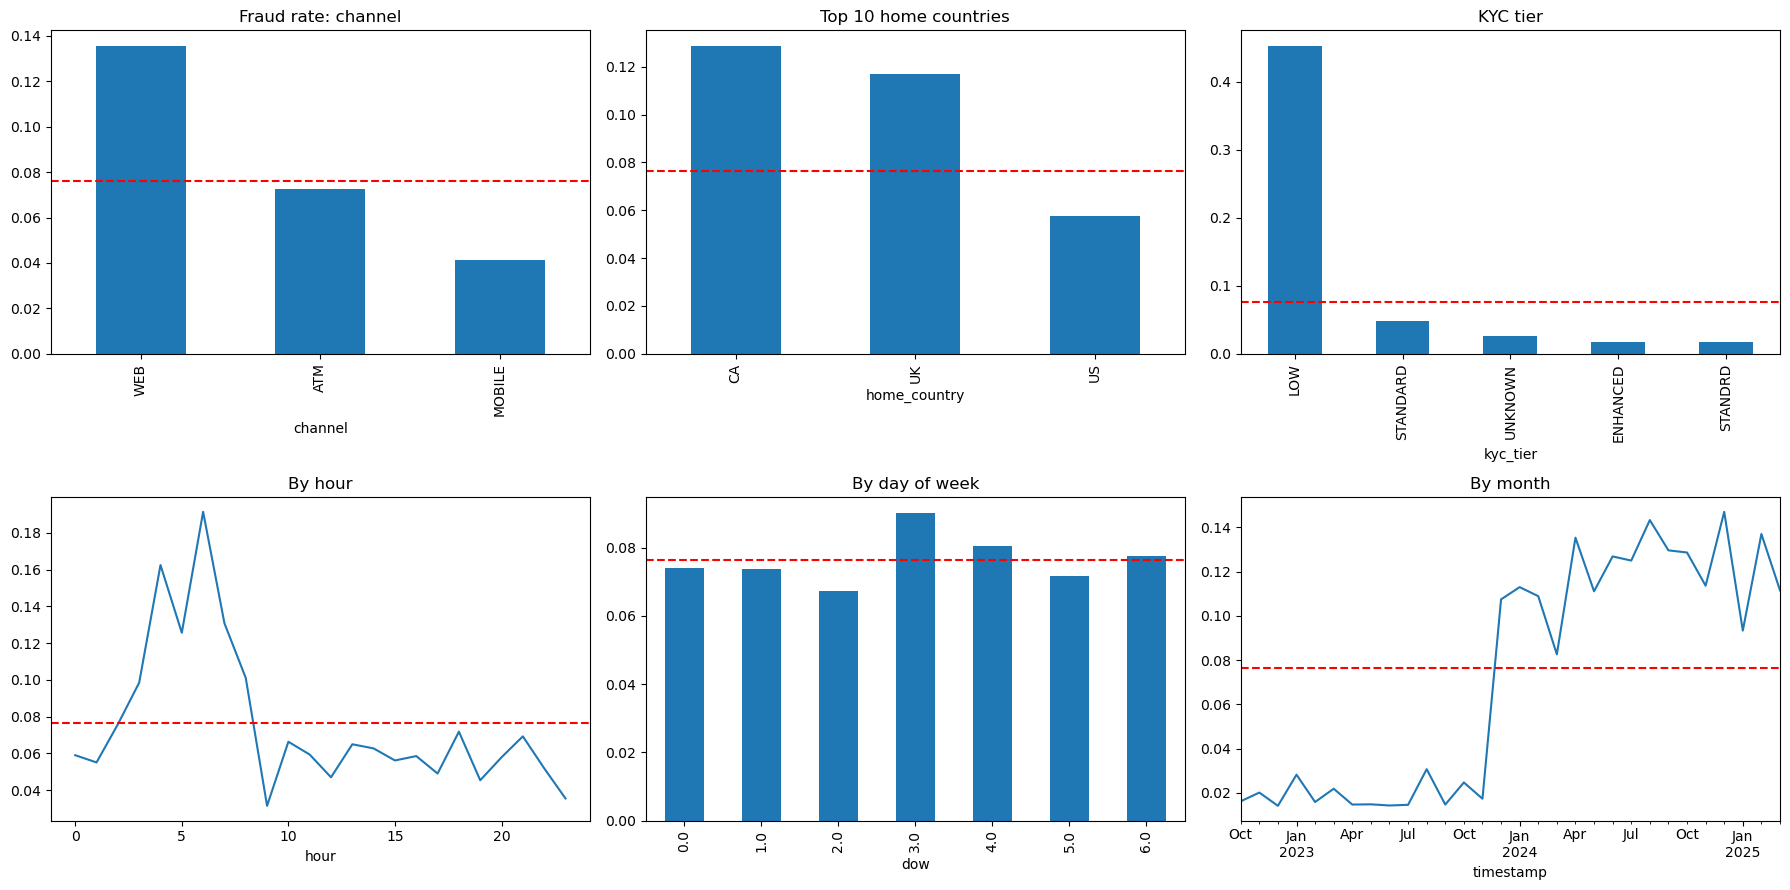

In [18]:
##fraud patterns by channel, geography, time
d = train.copy()
base = d.is_fraud.mean()

def rate(col, n=50):
    t = d.groupby(col)['is_fraud'].agg(n='count', rate='mean')
    return t[t.n >= n].sort_values('rate', ascending=False)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
rate('channel')['rate'].plot.bar(ax=ax[0,0], title='Fraud rate: channel')
rate('home_country')['rate'].head(10).plot.bar(ax=ax[0,1], title='Top 10 home countries')
rate('kyc_tier')['rate'].plot.bar(ax=ax[0,2], title='KYC tier')
d.groupby('hour')['is_fraud'].mean().plot(ax=ax[1,0], title='By hour')
d.groupby('dow')['is_fraud'].mean().plot.bar(ax=ax[1,1], title='By day of week')
d.groupby(d.timestamp.dt.to_period('M'))['is_fraud'].mean().plot(ax=ax[1,2], title='By month')
for a in ax.flat: a.axhline(base, color='r', ls='--')
plt.tight_layout(); plt.savefig('eda_patterns.png', dpi=120)

In [19]:
####fraud vs. legitimate behavior
num = d.select_dtypes('number').columns.drop(['is_fraud'])
cmp = d.groupby('is_fraud')[num].median().T
cmp['ratio'] = cmp[1] / cmp[0].replace(0, np.nan)
display(cmp.sort_values('ratio', key=lambda s: (s-1).abs(), ascending=False).head(15))

flags = ['new_device','location_mismatch','ip_home_mismatch','cross_currency','device_shared','enrichment_missing','first_txn_flag']
display(pd.DataFrame({f: d.groupby(f)['is_fraud'].mean() for f in flags}).T.rename(columns={0:'rate if 0',1:'rate if 1'}))

is_fraud,0,1,ratio
exchange_rate_src_to_dest,7.142857e+00,5.882353e+01,8.235294
amount_src,1.484800e+02,5.192200e+02,3.496902
amount_usd,1.539800e+02,5.248600e+02,3.408624
ip_risk_score,3.080000e-01,1.000000e+00,3.246753
fee,3.320000e+00,8.930000e+00,2.689759
hour_cos,-1.836970e-16,6.123234e-17,-0.333333
risk_score_internal,2.230000e-01,4.990000e-01,2.237668
device_txn_count_so_far,6.000000e+00,0.000000e+00,0.000000
account_age_days,2.980000e+02,2.100000e+01,0.070470
device_trust_score,7.810000e-01,2.530000e-01,0.323944


,rate if 0,rate if 1
new_device,0.043899,0.332669
location_mismatch,0.033439,0.309798
ip_home_mismatch,0.033254,0.313227
cross_currency,0.033019,0.082088
device_shared,NaN,NaN
enrichment_missing,0.077566,0.026549
first_txn_flag,0.020342,0.552604


In [20]:
#### correlation and multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
X = d[num].drop(columns=['hour','dow'], errors='ignore').fillna(d[num].median())
X = X.loc[:, X.std() > 0]

print(X.corrwith(d.is_fraud).sort_values(key=abs, ascending=False).head(15))   # vs target

c = X.corr().abs(); pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
print(pairs[pairs > 0.85].sort_values(ascending=False))                         # redundant pairs

Xs = X.sample(min(5000, len(X)), random_state=1)
print(pd.Series([vif(Xs.values, i) for i in range(Xs.shape[1])], index=Xs.columns).sort_values(ascending=False).head(10))

txn_velocity_24h             0.709257
txn_velocity_1h              0.639029
first_txn_flag               0.614934
chargeback_history_count     0.561724
risk_score_internal          0.552896
ip_risk_score                0.474702
ip_home_mismatch             0.380376
device_trust_score          -0.351280
account_age_days            -0.256169
corridor_risk                0.173581
device_txn_count_so_far     -0.155681
exchange_rate_src_to_dest    0.129754
amount_src                   0.116888
hour_sin                     0.096156
cnt_24h                     -0.091968
dtype: float64
txn_velocity_1h  txn_velocity_24h    0.957478
dtype: float64
cnt_1h                   298.305035
velocity_ratio_1h_24h    259.447998
txn_velocity_24h          22.027371
txn_velocity_1h           16.322532
device_trust_score        10.226634
risk_score_internal        9.011640
cross_currency             8.927624
cnt_7D                     7.345154
cnt_24h                    6.549440
ip_risk_score              5.0

In [21]:
###Feature shortlist (mutual information plus a quick forest)
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(Xs, d.loc[Xs.index,'is_fraud'], random_state=1), index=Xs.columns)
rf = RandomForestClassifier(300, n_jobs=-1, class_weight='balanced', random_state=1).fit(X, d.is_fraud)
imp = pd.Series(rf.feature_importances_, index=X.columns)
short = pd.DataFrame({'mi': mi, 'rf': imp}).rank(ascending=False).mean(axis=1).sort_values()
print(short.head(20))

ip_risk_score                 3.0
account_age_days              3.0
txn_velocity_24h              3.0
txn_velocity_1h               4.5
device_trust_score            5.0
risk_score_internal           5.0
first_txn_flag                5.5
device_txn_count_so_far       9.0
amount_zscore                 9.0
amount_src                   10.0
secs_since_prev_txn          11.0
amount_usd                   12.5
fee                          12.5
cnt_7D                       15.0
chargeback_history_count     15.5
ip_home_mismatch             16.5
fee_ratio                    16.5
amt_sum_24h                  18.0
exchange_rate_src_to_dest    18.0
corridor_risk                20.0
dtype: float64


## Step 4: Model Development

In [22]:
### setup (features, matrices, imports)
import re, joblib, optuna, shap, xgboost as xgb, lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import *
optuna.logging.set_verbosity(optuna.logging.WARNING)

FEATS = list(dict.fromkeys(list(short.head(20).index) + ['enrichment_missing','timestamp_invalid']))

def prep(df, cols=None):
    X = pd.concat([df[FEATS], pd.get_dummies(df[['channel','kyc_tier']].astype(str), dtype=float)], axis=1)
    X.columns = X.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)
    X = X.astype('float64')
    return X if cols is None else X.reindex(columns=cols, fill_value=0)

Xtr = prep(train); cols = list(Xtr.columns)
Xva, Xte = prep(val, cols), prep(test, cols)
ytr, yva, yte = train.is_fraud, val.is_fraud, test.is_fraud
spw = (ytr == 0).sum() / (ytr == 1).sum()
print(Xtr.shape, Xva.shape, Xte.shape, round(spw, 1))

(8954, 33) (888, 33) (1152, 33) 12.1


In [23]:
###Hyperparameter tuning (Optuna, time-ordered CV, PR-AUC)
tscv = TimeSeriesSplit(4)
mk_xgb = lambda p: xgb.XGBClassifier(**p, n_estimators=400, scale_pos_weight=spw, eval_metric='aucpr', n_jobs=-1, random_state=1)
mk_lgb = lambda p: lgb.LGBMClassifier(**p, n_estimators=400, subsample_freq=1, scale_pos_weight=spw, n_jobs=-1, random_state=1, verbose=-1)

def cv_ap(make, p):
    s = []
    for a, b in tscv.split(Xtr):
        m = make(p).fit(Xtr.iloc[a], ytr.iloc[a])
        s.append(average_precision_score(ytr.iloc[b], m.predict_proba(Xtr.iloc[b])[:, 1]))
    return np.mean(s)

def tune(name, make, space, n=25):
    st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=1))
    st.optimize(lambda t: cv_ap(make, space(t)), n_trials=n)
    st.trials_dataframe().to_csv(f'tuning_{name}.csv', index=False)
    print(name, round(st.best_value, 4), st.best_params)
    return st.best_params

sx = lambda t: dict(max_depth=t.suggest_int('max_depth', 3, 8), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True),
                    subsample=t.suggest_float('subsample', .6, 1), colsample_bytree=t.suggest_float('colsample_bytree', .6, 1),
                    min_child_weight=t.suggest_int('min_child_weight', 1, 10))
sl = lambda t: dict(num_leaves=t.suggest_int('num_leaves', 15, 127), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True),
                    subsample=t.suggest_float('subsample', .6, 1), colsample_bytree=t.suggest_float('colsample_bytree', .6, 1),
                    min_child_samples=t.suggest_int('min_child_samples', 10, 100))
bx = tune('xgboost', mk_xgb, sx)
bl = tune('lightgbm', mk_lgb, sl)

xgboost 0.6709 {'max_depth': 3, 'learning_rate': 0.020790728113316788, 'subsample': 0.6110226455598862, 'colsample_bytree': 0.994110746063661, 'min_child_weight': 10}
lightgbm 0.6623 {'num_leaves': 116, 'learning_rate': 0.02517965349134687, 'subsample': 0.615621913293153, 'colsample_bytree': 0.6679321678258275, 'min_child_samples': 89}


In [24]:
### train all four, comparison matrix on validation
models = {
 'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)),
 'RandomForest': make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(300, class_weight='balanced_subsample', min_samples_leaf=3, n_jobs=-1, random_state=1)),
 'XGBoost': mk_xgb(bx), 'LightGBM': mk_lgb(bl)}

def best_thr(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    return th[(2*pr*rc/(pr+rc+1e-9))[:-1].argmax()]

rows = {}
for n, m in models.items():
    m.fit(Xtr, ytr); joblib.dump(m, f'model_{n}.pkl')
    p = m.predict_proba(Xva)[:, 1]; t = best_thr(yva, p); yh = p >= t
    rows[n] = dict(PR_AUC=average_precision_score(yva, p), ROC_AUC=roc_auc_score(yva, p),
                   Precision=precision_score(yva, yh), Recall=recall_score(yva, yh), F1=f1_score(yva, yh), thr=t)
cmp = pd.DataFrame(rows).T.round(4).sort_values('PR_AUC', ascending=False)
display(cmp); cmp.to_csv('model_comparison.csv')
champ = cmp.index[0]; print('Champion:', champ)

,PR_AUC,ROC_AUC,Precision,Recall,F1,thr
LogReg,0.9393,0.9743,1.0,0.866,0.9282,0.9549
LightGBM,0.9390,0.9764,1.0,0.866,0.9282,0.9953
XGBoost,0.9385,0.9767,1.0,0.866,0.9282,0.9783
RandomForest,0.9352,0.9752,1.0,0.866,0.9282,0.8511


Champion: LogReg


## Step 5: Validation & Explainability

In [25]:
### one-time test evaluation, segments
m, thr = models[champ], cmp.loc[champ, 'thr']
p = m.predict_proba(Xte)[:, 1]; yh = p >= thr
print('Test PR-AUC', round(average_precision_score(yte, p), 4), '| ROC-AUC', round(roc_auc_score(yte, p), 4))
print(classification_report(yte, yh, digits=3)); print(confusion_matrix(yte, yh))

seg = test.assign(hit=yh)
display(seg.groupby('channel').apply(lambda g: pd.Series(dict(
    n=len(g), frauds=g.is_fraud.sum(), recall=recall_score(g.is_fraud, g.hit, zero_division=0),
    precision=precision_score(g.is_fraud, g.hit, zero_division=0)))))

Test PR-AUC 0.9764 | ROC-AUC 0.9854
              precision    recall  f1-score   support

           0      0.978     1.000     0.989       958
           1      1.000     0.887     0.940       194

    accuracy                          0.981      1152
   macro avg      0.989     0.943     0.964      1152
weighted avg      0.981     0.981     0.980      1152

[[958   0]
 [ 22 172]]


C:\Users\uSER\AppData\Local\Temp\ipykernel_13536\2996301349.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(seg.groupby('channel').apply(lambda g: pd.Series(dict(


,n,frauds,recall,precision
channel,,,,
ATM,90.0,16.0,1.000000,1.0
MOBILE,672.0,58.0,0.793103,1.0
UNKNOWN,2.0,0.0,0.000000,0.0
WEB,388.0,120.0,0.916667,1.0


In [26]:
FP_COST = 5.0          # <- SET: $ cost of reviewing one false alert
m = models[champ]
pv, pt = m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]

In [27]:
# 1) THRESHOLD, chosen on VALIDATION only: minimize expected loss
#    loss = $ amount of missed frauds + FP_COST * false alerts
amt_v = val.amount_usd.fillna(val.amount_usd.median()).values
yv = yva.values
ths = np.unique(np.quantile(pv, np.linspace(0.5, 0.999, 300)))
loss = lambda t: amt_v[(yv == 1) & (pv < t)].sum() + FP_COST * ((yv == 0) & (pv >= t)).sum()
thr = ths[int(np.argmin([loss(t) for t in ths]))]
print(f"Chosen threshold {thr:.4f} | val precision {precision_score(yv, pv>=thr):.3f} recall {recall_score(yv, pv>=thr):.3f}")

Chosen threshold 0.3009 | val precision 0.363 recall 0.979


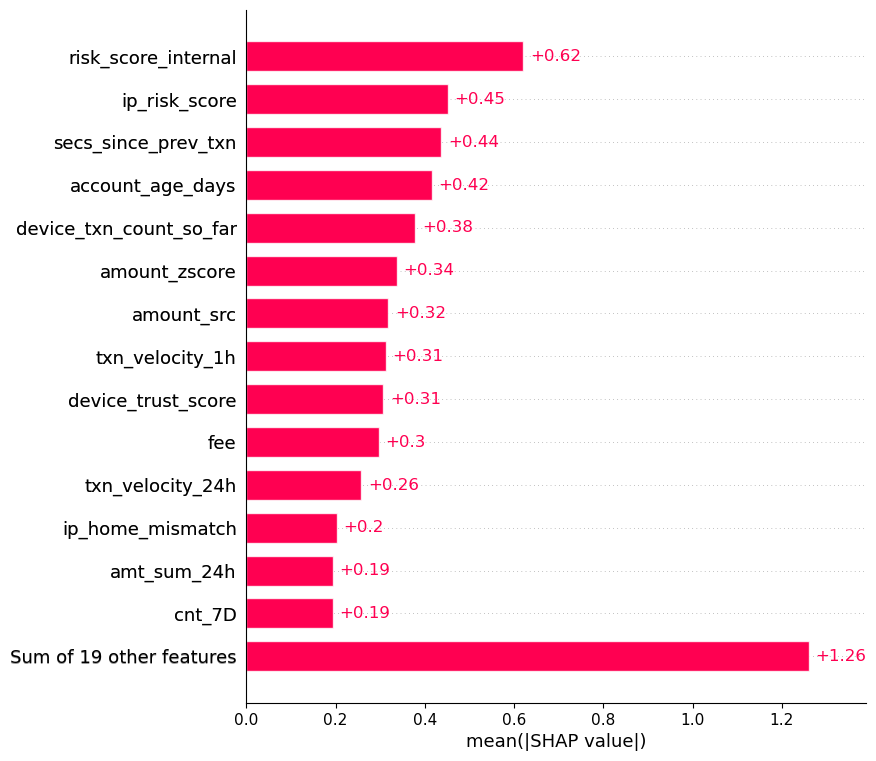

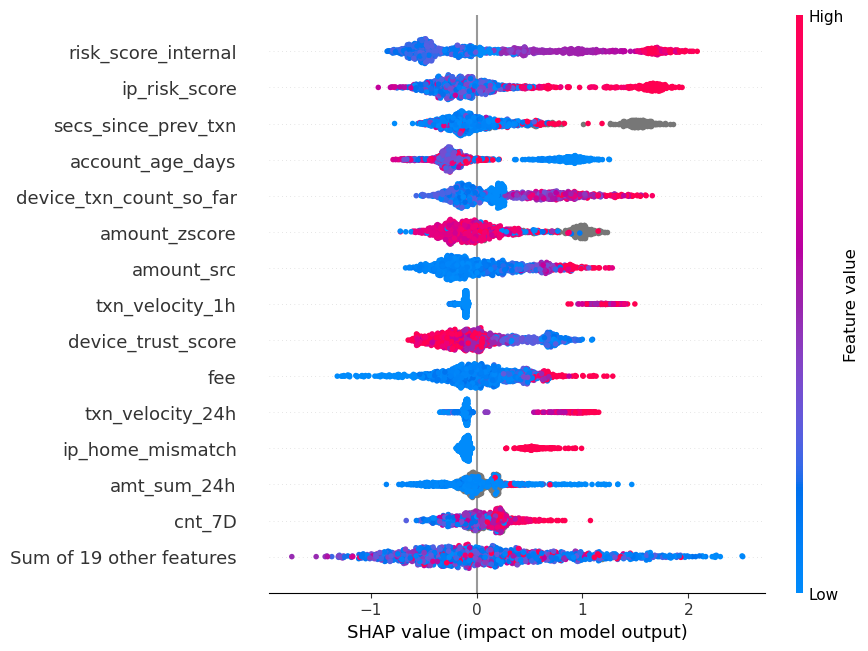

In [28]:
tm = models[champ] if champ in ('XGBoost', 'LightGBM') else models['LightGBM']   # needs a tree model
Xs = Xte.sample(min(2000, len(Xte)), random_state=1)
sv = shap.TreeExplainer(tm)(Xs)
if sv.values.ndim == 3: sv = sv[:, :, 1]

shap.plots.bar(sv, max_display=15)        # global importance
shap.plots.beeswarm(sv, max_display=15)   # direction and spread

## Step 6: Deployment (FastAPI + Docker)

In [29]:
from pathlib import Path
from importlib.metadata import version
import sys

root = Path('fraud-service'); (root / 'app').mkdir(parents=True, exist_ok=True)
(root / 'app/__init__.py').write_text('')

(root / 'app/main.py').write_text(r'''import json, os, joblib, pandas as pd
from typing import Dict, Optional
from fastapi import FastAPI
from pydantic import BaseModel

A = os.getenv("ARTIFACT_DIR", "artifacts")
V = os.getenv("MODEL_VERSION") or open(f"{A}/LATEST").read().strip()
model, meta = joblib.load(f"{A}/{V}/model.pkl"), json.load(open(f"{A}/{V}/meta.json"))
THR = float(os.getenv("THRESHOLD") or meta["threshold"])
app = FastAPI(title="Fraud Scoring API", version=V)

class Txn(BaseModel):
    transaction_id: str
    channel: str
    kyc_tier: str = "UNKNOWN"
    features: Dict[str, Optional[float]]

@app.get("/health")
def health():
    return {"status": "ok", "model_version": V, "threshold": THR}

@app.post("/score")
def score(t: Txn):
    X = pd.DataFrame([{k: t.features.get(k) for k in meta["base_feats"]}])
    cat = pd.DataFrame({"channel": [t.channel.upper()], "kyc_tier": [t.kyc_tier.upper()]})
    X = pd.concat([X, pd.get_dummies(cat, dtype=float)], axis=1)
    X.columns = X.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)
    X = X.astype("float64").reindex(columns=meta["feature_cols"], fill_value=0)
    p = float(model.predict_proba(X)[0, 1])
    return {"transaction_id": t.transaction_id, "fraud_score": p, "is_flagged": p >= THR, "model_version": V}
''')

pkgs = ['fastapi', 'uvicorn', 'pandas', 'numpy', 'scikit-learn', 'joblib', 'xgboost', 'lightgbm']
(root / 'requirements.txt').write_text('\n'.join(f'{p}=={version(p)}' for p in pkgs) + '\n')

py = f'{sys.version_info.major}.{sys.version_info.minor}'
(root / 'Dockerfile').write_text(f'''FROM python:{py}-slim
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 && rm -rf /var/lib/apt/lists/*
WORKDIR /srv
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app app
COPY artifacts artifacts
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
''')

(root / 'docker-compose.yml').write_text('''services:
  api:
    build: .
    ports: ["8000:8000"]
    volumes: ["./artifacts:/srv/artifacts:ro"]
''')
print(open(root / 'requirements.txt').read())

fastapi==0.143.3
uvicorn==0.54.0
pandas==2.3.3
numpy==2.3.5
scikit-learn==1.7.2
joblib==1.5.2
xgboost==3.4.1
lightgbm==4.7.0



## Step 7: Monitoring & Improvement

In [30]:
from evidently import Report, Dataset
from evidently.presets import DataDriftPreset

tm = models[champ]
mon = list(FEATS)                                   # numeric features the model uses
frame = lambda X, p: X[mon].assign(score=p)
ref = frame(Xva, tm.predict_proba(Xva)[:, 1])       # baseline = period the model was validated on
cur = frame(Xte, tm.predict_proba(Xte)[:, 1])     

rep = Report([DataDriftPreset()]).run(Dataset.from_pandas(cur), Dataset.from_pandas(ref))  # order: current, reference
rep.save_html('drift_report.html')
rep

In [31]:
from sklearn.metrics import recall_score, average_precision_score

def psi(a, b, bins=10):
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    q = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(q) < 3 or len(b) == 0: return 0.0
    ea = np.clip(np.histogram(a, q)[0] / len(a), 1e-6, None)
    eb = np.clip(np.histogram(np.clip(b, q[0], q[-1]), q)[0] / len(b), 1e-6, None)
    return float(np.sum((eb - ea) * np.log(eb / ea)))

drift = pd.Series({c: psi(ref[c].values, cur[c].values) for c in ref.columns}).sort_values(ascending=False)
print(drift.head(8).round(3))

rec_val = recall_score(yva, ref.score >= thr)       # recall at deployment sign-off
rec_cur = recall_score(yte, cur.score >= thr)       # needs matured labels for the current window
flag_ref, flag_cur = (ref.score >= thr).mean(), (cur.score >= thr).mean()

triggers = {
  'score PSI > 0.2':               drift['score'] > 0.2,
  '>30% of features PSI > 0.2':    (drift.drop('score') > 0.2).mean() > 0.3,
  'alert rate moved > 50%':        abs(flag_cur / flag_ref - 1) > 0.5,
  'recall dropped > 10 pts':       rec_cur < rec_val - 0.10,
}
print(pd.Series(triggers)); print('RETRAIN NOW' if any(triggers.values()) else 'Model stable')

amount_zscore              0.099
device_txn_count_so_far    0.078
risk_score_internal        0.069
ip_risk_score              0.067
amt_sum_24h                0.065
score                      0.064
fee                        0.063
amount_src                 0.061
dtype: float64
score PSI > 0.2               False
>30% of features PSI > 0.2    False
alert rate moved > 50%        False
recall dropped > 10 pts       False
dtype: bool
Model stable
